# Baseline Comparison and Adversarial Robustness Evaluation
## 1. Environment Setup and Partition Loading
This notebook evaluates the proposed Char-CNN against classical machine learning classifiers, character n-gram linear models, word-level neural networks, and subword neural architectures across clean holdout data, paired perturbation suites, nested 5-fold grouped cross-validation, and group-cluster bootstrap confidence intervals.

In [1]:
import os
import time
import random
import string
import pickle
import warnings

SEED = 42
os.environ['PYTHONHASHSEED'] = str(SEED)
os.environ['TF_DETERMINISTIC_OPS'] = '1'
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score, recall_score,
    f1_score, log_loss, roc_auc_score, average_precision_score
)
from sklearn.metrics.pairwise import cosine_similarity

import tensorflow as tf
from tensorflow.keras import regularizers
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.layers import (
    Input, Embedding, SpatialDropout1D, Conv1D, GlobalMaxPooling1D,
    Dense, Dropout, LSTM, concatenate, Multiply
)
from tensorflow.keras.models import Model, load_model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

def set_all_seeds(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)

set_all_seeds(SEED)

VALID_ALPHABET = string.ascii_lowercase + string.digits + " .,?!"
CHAR_TO_IDX = {ch: idx + 1 for idx, ch in enumerate(VALID_ALPHABET)}
VOCAB_SIZE = len(VALID_ALPHABET) + 1
MAX_LEN_CHAR = 300
MAX_LEN_WORD = 100

def clean_text(text):
    return ''.join([ch for ch in str(text).lower() if ch in VALID_ALPHABET]).strip()

class DeterministicCharTokenizer:
    def __init__(self, char_to_idx):
        self.char_to_idx = char_to_idx
    def texts_to_sequences(self, texts):
        return [[self.char_to_idx[ch] for ch in clean_text(t) if ch in self.char_to_idx] for t in texts]

def apply_obfuscation(text, technique, full_words=False):
    text = clean_text(text)
    words = text.split()
    if technique == 'substitution':
        return text.translate(str.maketrans('aeio', '4310'))
    elif technique == 'insertion':
        if full_words:
            return ' '.join(['.'.join(list(w)) if len(w) > 2 else w for w in words])
        new_words = []
        for idx, w in enumerate(words):
            if len(w) >= 4 and w.isalpha() and (idx % 2 == 0):
                new_words.append('.'.join(list(w)))
            else:
                new_words.append(w)
        res = ' '.join(new_words)
        return res if res != text else ' '.join(['.'.join(list(w)) if len(w) > 2 else w for w in words])
    elif technique == 'vowel_removal':
        if full_words:
            return ' '.join([w[0] + w[1:].translate(str.maketrans('', '', 'aeiou')) if (len(w) > 2 and w.isalpha()) else w for w in words])
        new_words = []
        for idx, w in enumerate(words):
            if len(w) >= 4 and w.isalpha() and (idx % 2 == 0):
                stripped = w[0] + w[1:].translate(str.maketrans('', '', 'aeiou'))
                new_words.append(stripped if len(stripped) >= 2 else w)
            else:
                new_words.append(w)
        res = ' '.join(new_words)
        return res if res != text else text.translate(str.maketrans('', '', 'aeiou'))
    elif technique == 'combined_leet_dot':
        t_leet = text.translate(str.maketrans('aeio', '4310'))
        return ' '.join(['.'.join(list(w)) if len(w) > 2 else w for w in t_leet.split()])
    elif technique == 'full_dot_evasion':
        return ' '.join(['.'.join(list(w)) if len(w) > 2 else w for w in words])
    elif technique == 'leet_vowel_drop':
        t_vow = apply_obfuscation(text, 'vowel_removal', full_words=True)
        return t_vow.translate(str.maketrans('aeio', '4310'))
    return text

def generate_augmented_split(df_train_split, mode='full_proposed', seed=SEED):
    rng = random.Random(seed)
    np_rng = np.random.RandomState(seed)
    spam_rows = df_train_split[df_train_split['label'] == 1]['cleaned_text'].tolist()
    ham_rows = df_train_split[df_train_split['label'] == 0]['cleaned_text'].tolist()

    if mode == 'clean_imbalanced':
        X_aug = spam_rows + ham_rows
        y_aug = np.array([1]*len(spam_rows) + [0]*len(ham_rows), dtype=np.int32)
        indices = np.arange(len(X_aug))
        np_rng.shuffle(indices)
        return [X_aug[i] for i in indices], y_aug[indices]

    X_aug, y_aug = [], []
    for text in spam_rows:
        c_orig = clean_text(text)
        if mode in ['oversample_only', 'ham_aug_only']:
            X_aug.extend([c_orig] * 5)
            y_aug.extend([1] * 5)
        else:
            X_aug.extend([
                c_orig, c_orig,
                clean_text(apply_obfuscation(c_orig, 'substitution')),
                clean_text(apply_obfuscation(c_orig, 'insertion')),
                clean_text(apply_obfuscation(c_orig, 'vowel_removal'))
            ])
            y_aug.extend([1] * 5)

    target_ham = len(spam_rows) * 5
    for idx_h in range(target_ham):
        c_base = clean_text(ham_rows[idx_h % len(ham_rows)])
        if mode in ['oversample_only', 'spam_aug_only']:
            X_aug.append(c_base)
            y_aug.append(0)
        else:
            ham_mod = c_base
            if (idx_h >= len(ham_rows)) and (rng.random() < 0.40):
                rand_num = rng.randint(1, 99)
                rand_code = rng.randint(100, 999)
                num_opts = [f" jam {rand_num}", f" tgl {rand_num}", f" {rand_num} orang", f" no {rand_code}", ""]
                word_opts = [" ya", " nih", " bro", " sis", " pak", ""]
                ham_mod = clean_text(ham_mod + rng.choice(num_opts) + rng.choice(word_opts))
            X_aug.append(ham_mod)
            y_aug.append(0)

    indices = np.arange(len(X_aug))
    np_rng.shuffle(indices)
    return [X_aug[i] for i in indices], np.array([y_aug[i] for i in indices], dtype=np.int32)

df_unique = pd.read_pickle('grouped_corpus_dataframe.pkl')
df_train = df_unique[df_unique['partition'] == 'TRAIN']
df_val = df_unique[df_unique['partition'] == 'VAL']
df_test = df_unique[df_unique['partition'] == 'TEST']

X_train_clean, y_train_aug = generate_augmented_split(df_train, mode='full_proposed', seed=SEED)
X_val_clean, y_val = df_val['cleaned_text'].tolist(), df_val['label'].values.astype(np.int32)
X_test_clean, y_test = df_test['cleaned_text'].tolist(), df_test['label'].values.astype(np.int32)

with open('tokenizer_char.pkl', 'rb') as handle:
    char_tokenizer = pickle.load(handle)

def encode_char(texts):
    return pad_sequences(char_tokenizer.texts_to_sequences(texts), maxlen=MAX_LEN_CHAR, padding='post', truncating='post')

def text_to_subwords(text):
    words = clean_text(text).split()
    subwords = []
    for w in words:
        w_pad = f"<{w}>"
        subwords.append(w)
        for n in (3, 4, 5):
            if len(w_pad) >= n:
                subwords.extend([w_pad[i:i+n] for i in range(len(w_pad) - n + 1)])
    return ' '.join(subwords)

## 2. Feature Extraction and Baseline Model Training
All models are trained on the identical 1,210-row augmented training split. Classical hyperparameters are tuned on the validation set, and all neural baselines use the identical 35-epoch ceiling and early stopping (`patience=5`) on validation loss. Pre-padding is used for the recurrent Word-LSTM so that final time-step hidden states are not zeroed out by trailing pad tokens.

In [2]:
tfidf_word = TfidfVectorizer(max_features=5000)
X_tr_w_tfidf = tfidf_word.fit_transform(X_train_clean)
X_val_w_tfidf = tfidf_word.transform(X_val_clean)
X_te_w_tfidf = tfidf_word.transform(X_test_clean)

tfidf_char = TfidfVectorizer(analyzer='char', ngram_range=(3, 5), max_features=10000, sublinear_tf=True)
X_tr_c_tfidf = tfidf_char.fit_transform(X_train_clean)
X_val_c_tfidf = tfidf_char.transform(X_val_clean)
X_te_c_tfidf = tfidf_char.transform(X_test_clean)

word_tokenizer = Tokenizer(num_words=5000, oov_token='<OOV>')
word_tokenizer.fit_on_texts(X_train_clean)

def encode_word_post(texts):
    return pad_sequences(word_tokenizer.texts_to_sequences(texts), maxlen=MAX_LEN_WORD, padding='post', truncating='post')

def encode_word_pre(texts):
    return pad_sequences(word_tokenizer.texts_to_sequences(texts), maxlen=MAX_LEN_WORD, padding='pre', truncating='post')

X_tr_word_post = encode_word_post(X_train_clean)
X_val_word_post = encode_word_post(X_val_clean)
X_te_word_post = encode_word_post(X_test_clean)

X_tr_word_pre = encode_word_pre(X_train_clean)
X_val_word_pre = encode_word_pre(X_val_clean)
X_te_word_pre = encode_word_pre(X_test_clean)

subword_tokenizer = Tokenizer(num_words=10000, filters='', oov_token='<OOV>')
subword_tokenizer.fit_on_texts([text_to_subwords(t) for t in X_train_clean])
def encode_subword(texts):
    return pad_sequences(subword_tokenizer.texts_to_sequences([text_to_subwords(t) for t in texts]), maxlen=250, padding='post', truncating='post')

X_tr_sub = encode_subword(X_train_clean)
X_val_sub = encode_subword(X_val_clean)
X_te_sub = encode_subword(X_test_clean)

X_tr_char = encode_char(X_train_clean)
X_val_char = encode_char(X_val_clean)
X_te_char = encode_char(X_test_clean)

def tune_classical_on_val(X_tr_w, y_tr, X_va_w, y_va, X_tr_c, X_va_c):
    b_alpha, b_nb_sc = 1.0, (-1.0, -999.0)
    for alpha in [0.5, 1.0, 1.5, 2.0]:
        m = MultinomialNB(alpha=alpha).fit(X_tr_w, y_tr)
        sc = (f1_score(y_va, m.predict(X_va_w)), -log_loss(y_va, m.predict_proba(X_va_w)))
        if sc > b_nb_sc: b_nb_sc, b_alpha = sc, alpha

    b_w_c, b_w_sc = 1.0, (-1.0, -999.0)
    for c_val in [0.5, 1.0, 2.0, 5.0]:
        m = SVC(C=c_val, kernel='linear', probability=True, random_state=SEED).fit(X_tr_w, y_tr)
        sc = (f1_score(y_va, m.predict(X_va_w)), -log_loss(y_va, m.predict_proba(X_va_w)))
        if sc > b_w_sc: b_w_sc, b_w_c = sc, c_val

    b_c_c, b_c_sc = 1.0, (-1.0, -999.0)
    for c_val in [0.5, 1.0, 2.0, 5.0]:
        m = SVC(C=c_val, kernel='linear', probability=True, random_state=SEED).fit(X_tr_c, y_tr)
        sc = (f1_score(y_va, m.predict(X_va_c)), -log_loss(y_va, m.predict_proba(X_va_c)))
        if sc > b_c_sc: b_c_sc, b_c_c = sc, c_val

    return b_alpha, b_w_c, b_c_c

best_nb_alpha, best_svm_c, best_charsvm_c = tune_classical_on_val(
    X_tr_w_tfidf, y_train_aug, X_val_w_tfidf, y_val, X_tr_c_tfidf, X_val_c_tfidf
)
print(f"Validation-tuned hyperparameters: NB alpha={best_nb_alpha}, Word-SVM C={best_svm_c}, Char-SVM C={best_charsvm_c}")

nb = MultinomialNB(alpha=best_nb_alpha).fit(X_tr_w_tfidf, y_train_aug)
dt = DecisionTreeClassifier(random_state=SEED).fit(X_tr_w_tfidf, y_train_aug)
svm_word = SVC(C=best_svm_c, kernel='linear', probability=True, random_state=SEED).fit(X_tr_w_tfidf, y_train_aug)
rf = RandomForestClassifier(n_estimators=100, random_state=SEED).fit(X_tr_w_tfidf, y_train_aug)
lr = LogisticRegression(C=best_svm_c, max_iter=1000, random_state=SEED).fit(X_tr_w_tfidf, y_train_aug)
svm_char = SVC(C=best_charsvm_c, kernel='linear', probability=True, random_state=SEED).fit(X_tr_c_tfidf, y_train_aug)

def build_word_cnn(seed=SEED):
    set_all_seeds(seed)
    inp = Input(shape=(MAX_LEN_WORD,))
    x = Embedding(5000, 50, embeddings_regularizer=regularizers.l2(1e-4))(inp)
    x = SpatialDropout1D(0.2, seed=seed)(x)
    x = Conv1D(64, 3, activation='relu', kernel_regularizer=regularizers.l2(1e-4))(x)
    x = GlobalMaxPooling1D()(x)
    x = Dense(64, activation='relu', kernel_regularizer=regularizers.l2(1e-4))(x)
    out = Dense(1, activation='sigmoid')(Dropout(0.5, seed=seed)(x))
    m = Model(inp, out)
    m.compile(optimizer=Adam(learning_rate=3e-4), loss='binary_crossentropy', metrics=['accuracy'])
    return m

def build_word_lstm(seed=SEED):
    set_all_seeds(seed)
    inp = Input(shape=(MAX_LEN_WORD,))
    x = Embedding(5000, 50, embeddings_regularizer=regularizers.l2(1e-4))(inp)
    x = SpatialDropout1D(0.2, seed=seed)(x)
    x = LSTM(32)(x)
    x = Dense(32, activation='relu', kernel_regularizer=regularizers.l2(1e-4))(x)
    out = Dense(1, activation='sigmoid')(Dropout(0.3, seed=seed)(x))
    m = Model(inp, out)
    m.compile(optimizer=Adam(learning_rate=3e-4), loss='binary_crossentropy', metrics=['accuracy'])
    return m

def build_subword_cnn(seed=SEED):
    set_all_seeds(seed)
    inp = Input(shape=(250,))
    x = Embedding(10000, 50, embeddings_regularizer=regularizers.l2(1e-4))(inp)
    x = SpatialDropout1D(0.2, seed=seed)(x)
    x = Conv1D(64, 3, activation='relu', kernel_regularizer=regularizers.l2(1e-4))(x)
    x = GlobalMaxPooling1D()(x)
    x = Dense(64, activation='relu', kernel_regularizer=regularizers.l2(1e-4))(x)
    out = Dense(1, activation='sigmoid')(Dropout(0.5, seed=seed)(x))
    m = Model(inp, out)
    m.compile(optimizer=Adam(learning_rate=3e-4), loss='binary_crossentropy', metrics=['accuracy'])
    return m

def build_char_cnn(vocab_size=VOCAB_SIZE, embed_dim=50, max_len=MAX_LEN_CHAR, seed=SEED):
    set_all_seeds(seed)
    inputs = Input(shape=(max_len,), dtype='int32', name="Input_SMS")
    x = Embedding(
        input_dim=vocab_size, output_dim=embed_dim,
        embeddings_regularizer=regularizers.l2(1e-4),
        name="Embedding"
    )(inputs)
    mask = Embedding(
        input_dim=vocab_size, output_dim=1,
        embeddings_initializer='ones',
        trainable=False,
        name="Zero_Padding_Mask"
    )(inputs)
    x = Multiply(name="Masked_Embedding")([x, mask])
    x = SpatialDropout1D(0.2, seed=seed, name="SpatialDropout")(x)

    conv_3 = Conv1D(filters=64, kernel_size=3, activation='relu', kernel_regularizer=regularizers.l2(1e-4), name="Conv1D_3")(x)
    conv_4 = Conv1D(filters=64, kernel_size=4, activation='relu', kernel_regularizer=regularizers.l2(1e-4), name="Conv1D_4")(x)
    conv_5 = Conv1D(filters=64, kernel_size=5, activation='relu', kernel_regularizer=regularizers.l2(1e-4), name="Conv1D_5")(x)

    pool_3 = GlobalMaxPooling1D(name="GMP_3")(conv_3)
    pool_4 = GlobalMaxPooling1D(name="GMP_4")(conv_4)
    pool_5 = GlobalMaxPooling1D(name="GMP_5")(conv_5)

    merged = concatenate([pool_3, pool_4, pool_5], name="Concat_Pools")
    dense = Dense(128, activation='relu', kernel_regularizer=regularizers.l2(1e-4), name="Dense_128")(merged)
    dropout = Dropout(0.5, seed=seed, name="Dropout_05")(dense)
    outputs = Dense(1, activation='sigmoid', name="Sigmoid_Out")(dropout)

    model = Model(inputs=inputs, outputs=outputs, name="Proposed_Char_CNN")
    mask_w = np.ones((vocab_size, 1), dtype=np.float32)
    mask_w[0, 0] = 0.0
    model.get_layer("Zero_Padding_Mask").set_weights([mask_w])
    model.compile(optimizer=Adam(learning_rate=3e-4), loss='binary_crossentropy', metrics=['accuracy'])
    return model

word_cnn = build_word_cnn(SEED)
word_cnn.fit(X_tr_word_post, y_train_aug, epochs=35, batch_size=32, validation_data=(X_val_word_post, y_val),
             callbacks=[EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)], shuffle=False, verbose=0)

word_lstm = build_word_lstm(SEED)
word_lstm.fit(X_tr_word_pre, y_train_aug, epochs=35, batch_size=32, validation_data=(X_val_word_pre, y_val),
              callbacks=[EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)], shuffle=False, verbose=0)

subword_cnn = build_subword_cnn(SEED)
subword_cnn.fit(X_tr_sub, y_train_aug, epochs=35, batch_size=32, validation_data=(X_val_sub, y_val),
                callbacks=[EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)], shuffle=False, verbose=0)

char_cnn = load_model('char_cnn_spam_model.keras')
print("All baseline models trained and Char-CNN checkpoint loaded.")

Validation-tuned hyperparameters: NB alpha=0.5, Word-SVM C=2.0, Char-SVM C=1.0
All baseline models trained and Char-CNN checkpoint loaded.


## 3. Holdout Test Set Benchmark and Validation Operating Thresholds
Models are evaluated on the held-out test set ($N = 51$), reporting integer confusion counts, accuracy, precision, recall, legitimate false-positive rate (FPR), F1-score, ROC-AUC, PR-AUC, and validation-tuned decision thresholds.

                       Model  TP  FP  TN  FN  Accuracy  SPAM_Precision  SPAM_Recall  HAM_FPR  SPAM_F1  ROC_AUC  PR_AUC  Val_Th
                 Naive Bayes  41   1   9   0    0.9804          0.9762       1.0000   0.1000   0.9880   0.9805  0.9949  0.3500
               Decision Tree  34   4   6   7    0.7843          0.8947       0.8293   0.4000   0.8608   0.7146  0.8792  0.3500
           SVM (Linear Word)  41   4   6   0    0.9216          0.9111       1.0000   0.4000   0.9535   0.9659  0.9903  0.7000
               Random Forest  40   3   7   1    0.9216          0.9302       0.9756   0.3000   0.9524   0.8915  0.9486  0.7000
         Logistic Regression  41   2   8   0    0.9608          0.9535       1.0000   0.2000   0.9762   0.9707  0.9919  0.6500
                    Word-CNN  41   3   7   0    0.9412          0.9318       1.0000   0.3000   0.9647   0.9561  0.9880  0.3500
                   Word-LSTM  41   0  10   0    1.0000          1.0000       1.0000   0.0000   1.0000   1.0000 

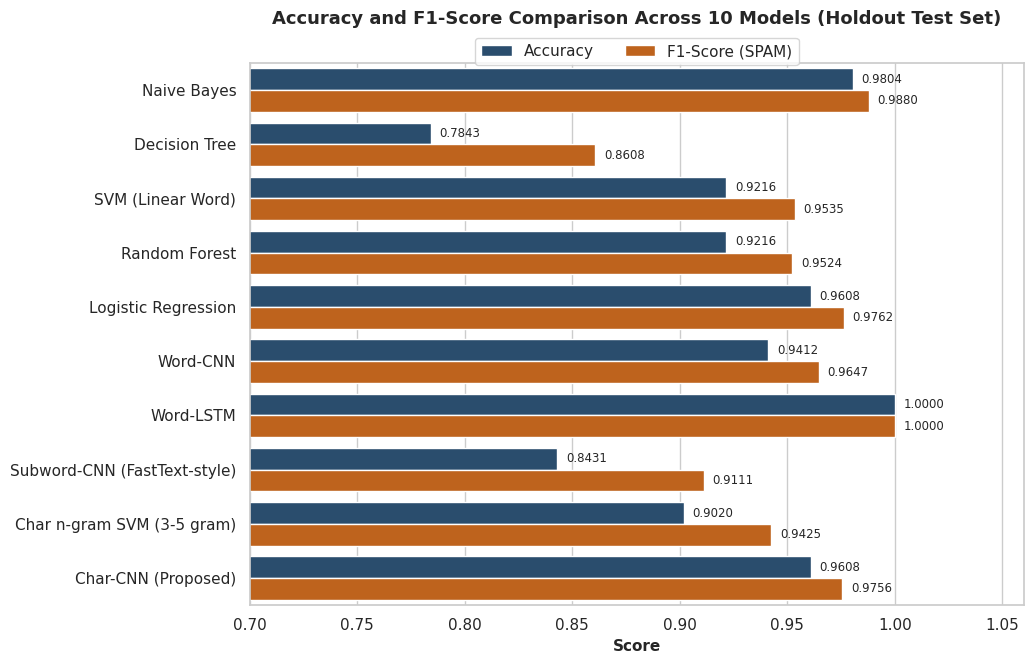

In [3]:
models_registry = [
    ("Naive Bayes", nb, 'word_tfidf'),
    ("Decision Tree", dt, 'word_tfidf'),
    ("SVM (Linear Word)", svm_word, 'word_tfidf'),
    ("Random Forest", rf, 'word_tfidf'),
    ("Logistic Regression", lr, 'word_tfidf'),
    ("Word-CNN", word_cnn, 'word_seq_post'),
    ("Word-LSTM", word_lstm, 'word_seq_pre'),
    ("Subword-CNN (FastText-style)", subword_cnn, 'subword_seq'),
    ("Char n-gram SVM (3-5 gram)", svm_char, 'char_tfidf'),
    ("Char-CNN (Proposed)", char_cnn, 'char_seq')
]

def predict_probs(model, m_type, raw_texts):
    cleaned = [clean_text(t) for t in raw_texts]
    if m_type == 'word_tfidf':
        return model.predict_proba(tfidf_word.transform(cleaned))[:, 1]
    elif m_type == 'char_tfidf':
        return model.predict_proba(tfidf_char.transform(cleaned))[:, 1]
    elif m_type == 'word_seq_post':
        return model.predict(encode_word_post(cleaned), verbose=0).flatten()
    elif m_type == 'word_seq_pre':
        return model.predict(encode_word_pre(cleaned), verbose=0).flatten()
    elif m_type == 'subword_seq':
        return model.predict(encode_subword(cleaned), verbose=0).flatten()
    else:
        return model.predict(encode_char(cleaned), verbose=0).flatten()

def select_val_threshold(val_probs, y_va):
    best_th, best_sc = 0.50, (-1.0, -1.0)
    for th in np.arange(0.35, 0.75, 0.05):
        p_v = (val_probs >= th).astype(int)
        fpr_v = sum((p_v == 1) & (y_va == 0)) / max(1, sum(y_va == 0))
        f1_v = f1_score(y_va, p_v, zero_division=0)
        sc = (1.0 if fpr_v <= 0.10 else 0.0, f1_v - 0.2 * fpr_v)
        if sc > best_sc:
            best_sc, best_th = sc, float(np.round(th, 2))
    return best_th

benchmark_rows = []
per_msg_preds = pd.DataFrame({
    'msg_id': df_test['msg_id'].values,
    'group_id': df_test['group_id'].values,
    'true_label': y_test
})

for name, model, m_type in models_registry:
    val_p = predict_probs(model, m_type, X_val_clean)
    opt_th = select_val_threshold(val_p, y_val)

    probs = predict_probs(model, m_type, X_test_clean)
    preds = (probs >= 0.5).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, preds).ravel()

    col_key = name.replace(' ', '_').replace('(', '').replace(')', '').replace('-', '_')
    per_msg_preds[f"{col_key}_prob"] = np.round(probs, 4)
    per_msg_preds[f"{col_key}_pred"] = preds

    benchmark_rows.append({
        'Model': name,
        'TP': int(tp), 'FP': int(fp), 'TN': int(tn), 'FN': int(fn),
        'Accuracy': accuracy_score(y_test, preds),
        'SPAM_Precision': precision_score(y_test, preds, zero_division=0),
        'SPAM_Recall': recall_score(y_test, preds, zero_division=0),
        'HAM_FPR': fp / (fp + tn) if (fp + tn) > 0 else 0.0,
        'SPAM_F1': f1_score(y_test, preds, zero_division=0),
        'ROC_AUC': roc_auc_score(y_test, probs),
        'PR_AUC': average_precision_score(y_test, probs),
        'Val_Th': opt_th
    })

per_msg_preds.to_csv('test_predictions_manifest.csv', index=False)
df_bench = pd.DataFrame(benchmark_rows)
df_bench.to_csv('benchmark_holdout_results.csv', index=False)

print(df_bench.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

plt.figure(figsize=(10.5, 6.8))
sns.set_theme(style="whitegrid")
df_plot = pd.melt(df_bench, id_vars=['Model'], value_vars=['Accuracy', 'SPAM_F1'], var_name='Metric', value_name='Score')
df_plot['Metric'] = df_plot['Metric'].replace({'SPAM_F1': 'F1-Score (SPAM)'})
ax = sns.barplot(y='Model', x='Score', hue='Metric', data=df_plot, palette=['#1f4e78', '#d95f02'])
plt.title('Accuracy and F1-Score Comparison Across 10 Models (Holdout Test Set)', fontsize=13, fontweight='bold', pad=28)
plt.xlim(0.70, 1.06)
plt.xlabel('Score', fontsize=11, fontweight='bold')
plt.ylabel('')
for p in ax.patches:
    w = p.get_width()
    if w > 0:
        ax.annotate(f"{w:.4f}", (w + 0.004, p.get_y() + p.get_height() / 2.), va='center', fontsize=8.5)
plt.legend(loc='upper center', bbox_to_anchor=(0.5, 1.06), ncol=2, frameon=True)
plt.tight_layout()
plt.savefig('fig4_model_comparison.png', dpi=300)
plt.savefig('fig4_model_comparison.pdf')
plt.show()

## 4. Paired Adversarial Robustness and Granular Perturbation Breakdown
Models are evaluated across natural obfuscations in the test set, seen perturbation types, unseen compound perturbations, paired legitimate messages containing numeric and colloquial suffixes, and two illustrative stress-test examples.

In [4]:
test_spam_raw = df_test[df_test['label'] == 1]['cleaned_text'].tolist()
test_ham_raw = df_test[df_test['label'] == 0]['cleaned_text'].tolist()

suite_seen_leet = [apply_obfuscation(t, 'substitution') for t in test_spam_raw]
suite_seen_dot = [apply_obfuscation(t, 'insertion') for t in test_spam_raw]
suite_seen_vowel = [apply_obfuscation(t, 'vowel_removal') for t in test_spam_raw]
suite_seen_all = suite_seen_leet + suite_seen_dot + suite_seen_vowel

suite_unseen_full_dot = [apply_obfuscation(t, 'full_dot_evasion', full_words=True) for t in test_spam_raw]
suite_unseen_combo = [apply_obfuscation(t, 'combined_leet_dot', full_words=True) for t in test_spam_raw]
suite_unseen_leet_vow = [apply_obfuscation(t, 'leet_vowel_drop', full_words=True) for t in test_spam_raw]
suite_unseen_all = suite_unseen_full_dot + suite_unseen_combo + suite_unseen_leet_vow

suite_ham_traps = []
for t in test_ham_raw:
    for suffix in [" jam 10 ya", " tgl 25 pak", " 15 orang bro", " no 482 nih"]:
        suite_ham_traps.append(clean_text(t + suffix))

target_1_spam = "s.3.l.4.m.a.t n.0.m.0.r a.n.d.a m.3.m.3.n.4.n.g.k.4.n 10 j.u.t.a"
target_2_ham = "Tolong belikan martabak manis rasa keju coklat di simpang depan ya, jangan lupa bawa payung karena hujan turun deras."

natural_obf_mask = df_test['cleaned_text'].str.contains(r'\d|\b[b-df-hj-np-tv-z]{3,}\b|\w\.\w', regex=True).values
X_test_nat = [t for t, m in zip(X_test_clean, natural_obf_mask) if m]
y_test_nat = y_test[natural_obf_mask]

robustness_rows, granular_rows = [], []
for name, model, m_type in models_registry:
    rec_clean = recall_score(y_test, (predict_probs(model, m_type, X_test_clean) >= 0.5).astype(int))
    preds_seen = (predict_probs(model, m_type, suite_seen_all) >= 0.5).astype(int)
    preds_unseen = (predict_probs(model, m_type, suite_unseen_all) >= 0.5).astype(int)
    preds_ham_trap = (predict_probs(model, m_type, suite_ham_traps) >= 0.5).astype(int)

    y_adv_true = np.array([1]*(len(suite_seen_all) + len(suite_unseen_all)) + [0]*len(suite_ham_traps))
    y_adv_pred = np.concatenate([preds_seen, preds_unseen, preds_ham_trap])
    adv_f1 = f1_score(y_adv_true, y_adv_pred, zero_division=0)

    p_t1 = predict_probs(model, m_type, [target_1_spam])[0]
    p_t2 = predict_probs(model, m_type, [target_2_ham])[0]

    robustness_rows.append({
        'Model': name,
        'Clean_Recall': rec_clean,
        'Seen_Obf_Recall': np.mean(preds_seen == 1),
        'Unseen_Obf_Recall': np.mean(preds_unseen == 1),
        'Numeric_HAM_FPR': np.mean(preds_ham_trap == 1),
        'Adversarial_F1': adv_f1,
        'Target1_Obf_SPAM': f"{'SPAM' if p_t1>=0.5 else 'HAM'} ({p_t1:.3f})",
        'Target2_Long_HAM': f"{'SPAM' if p_t2>=0.5 else 'HAM'} ({p_t2:.3f})"
    })

    p_nat = (predict_probs(model, m_type, X_test_nat) >= 0.5).astype(int)
    granular_rows.append({
        'Model': name,
        'Nat_Obf_F1': f1_score(y_test_nat, p_nat, zero_division=0),
        'Seen_Leet': np.mean(predict_probs(model, m_type, suite_seen_leet) >= 0.5),
        'Seen_Dot': np.mean(predict_probs(model, m_type, suite_seen_dot) >= 0.5),
        'Seen_Vowel': np.mean(predict_probs(model, m_type, suite_seen_vowel) >= 0.5),
        'Unseen_FullDot': np.mean(predict_probs(model, m_type, suite_unseen_full_dot) >= 0.5),
        'Unseen_LeetDot': np.mean(predict_probs(model, m_type, suite_unseen_combo) >= 0.5),
        'Unseen_LeetVow': np.mean(predict_probs(model, m_type, suite_unseen_leet_vow) >= 0.5)
    })

df_robust = pd.DataFrame(robustness_rows)
df_robust.to_csv('paired_robustness_suite_results.csv', index=False)
print("Paired Robustness Summary:")
print(df_robust.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

df_granular = pd.DataFrame(granular_rows)
df_granular.to_csv('granular_perturbation_breakdown.csv', index=False)
print("\nGranular Perturbation Breakdown:")
print(df_granular.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

Paired Robustness Summary:
                       Model  Clean_Recall  Seen_Obf_Recall  Unseen_Obf_Recall  Numeric_HAM_FPR  Adversarial_F1 Target1_Obf_SPAM Target2_Long_HAM
                 Naive Bayes        1.0000           0.9837             0.8862           0.0750          0.9603     SPAM (0.664)      HAM (0.384)
               Decision Tree        0.8293           0.8943             0.9837           0.3250          0.9429     SPAM (1.000)      HAM (0.000)
           SVM (Linear Word)        1.0000           1.0000             0.9919           0.2750          0.9761     SPAM (0.996)     SPAM (0.927)
               Random Forest        0.9756           0.9756             0.9919           0.1250          0.9817     SPAM (0.990)      HAM (0.450)
         Logistic Regression        1.0000           1.0000             0.9919           0.1500          0.9859     SPAM (0.868)     SPAM (0.671)
                    Word-CNN        1.0000           1.0000             1.0000           0.2000  

## 5. Nested Five-Fold Stratified Grouped Cross-Validation
Outer-fold evaluation across all five template-grouped partitions quantifies generalization stability (mean $\pm$ standard deviation), with hyperparameters and early-stopping checkpoints selected strictly within each fold's inner validation split.

In [5]:
cv_records, cv_pred_rows = [], []
for fold_id in range(5):
    val_fold_id = (fold_id + 1) % 5
    df_te_cv = df_unique[df_unique['outer_fold'] == fold_id]
    df_va_cv = df_unique[df_unique['outer_fold'] == val_fold_id]
    df_tr_cv = df_unique[~df_unique['outer_fold'].isin([fold_id, val_fold_id])]

    X_tr_cv, y_tr_cv = generate_augmented_split(df_tr_cv, mode='full_proposed', seed=SEED + fold_id)
    X_va_cv, y_va_cv = df_va_cv['cleaned_text'].tolist(), df_va_cv['label'].values.astype(np.int32)
    X_te_cv, y_te_cv = df_te_cv['cleaned_text'].tolist(), df_te_cv['label'].values.astype(np.int32)

    vec_w_cv = TfidfVectorizer(max_features=5000).fit(X_tr_cv)
    vec_c_cv = TfidfVectorizer(analyzer='char', ngram_range=(3, 5), max_features=10000, sublinear_tf=True).fit(X_tr_cv)

    X_tr_w_cv, X_va_w_cv, X_te_w_cv = vec_w_cv.transform(X_tr_cv), vec_w_cv.transform(X_va_cv), vec_w_cv.transform(X_te_cv)
    X_tr_c_cv, X_va_c_cv, X_te_c_cv = vec_c_cv.transform(X_tr_cv), vec_c_cv.transform(X_va_cv), vec_c_cv.transform(X_te_cv)

    # Inner-fold hyperparameter selection
    f_alpha, f_w_c, f_c_c = tune_classical_on_val(X_tr_w_cv, y_tr_cv, X_va_w_cv, y_va_cv, X_tr_c_cv, X_va_c_cv)

    m_nb_cv = MultinomialNB(alpha=f_alpha).fit(X_tr_w_cv, y_tr_cv)
    m_svm_cv = SVC(C=f_w_c, kernel='linear', probability=True, random_state=SEED + fold_id).fit(X_tr_w_cv, y_tr_cv)
    m_csvm_cv = SVC(C=f_c_c, kernel='linear', probability=True, random_state=SEED + fold_id).fit(X_tr_c_cv, y_tr_cv)

    X_tr_pad_cv = encode_char(X_tr_cv)
    X_va_pad_cv = encode_char(X_va_cv)
    X_te_pad_cv = encode_char(X_te_cv)

    m_ccnn_cv = build_char_cnn(seed=SEED + fold_id)
    m_ccnn_cv.fit(X_tr_pad_cv, y_tr_cv, epochs=35, batch_size=32, validation_data=(X_va_pad_cv, y_va_cv),
                  callbacks=[EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)], shuffle=False, verbose=0)

    fold_probs = {
        'Naive Bayes': m_nb_cv.predict_proba(X_te_w_cv)[:, 1],
        'SVM (Linear Word)': m_svm_cv.predict_proba(X_te_w_cv)[:, 1],
        'Char n-gram SVM': m_csvm_cv.predict_proba(X_te_c_cv)[:, 1],
        'Char-CNN (Proposed)': m_ccnn_cv.predict(X_te_pad_cv, verbose=0).flatten()
    }

    for i_m, msg_id_val in enumerate(df_te_cv['msg_id'].values):
        cv_pred_rows.append({
            'Fold': fold_id, 'msg_id': msg_id_val, 'true_label': int(y_te_cv[i_m]),
            'NB_prob': round(float(fold_probs['Naive Bayes'][i_m]), 4),
            'WordSVM_prob': round(float(fold_probs['SVM (Linear Word)'][i_m]), 4),
            'CharSVM_prob': round(float(fold_probs['Char n-gram SVM'][i_m]), 4),
            'CharCNN_prob': round(float(fold_probs['Char-CNN (Proposed)'][i_m]), 4)
        })

    for m_name, prob_arr in fold_probs.items():
        p_arr = (prob_arr >= 0.5).astype(int)
        tn_f, fp_f, fn_f, tp_f = confusion_matrix(y_te_cv, p_arr).ravel()
        cv_records.append({
            'Fold': fold_id, 'Model': m_name,
            'Accuracy': accuracy_score(y_te_cv, p_arr),
            'SPAM_Recall': recall_score(y_te_cv, p_arr, zero_division=0),
            'HAM_FPR': fp_f / (fp_f + tn_f) if (fp_f + tn_f) > 0 else 0.0,
            'SPAM_F1': f1_score(y_te_cv, p_arr, zero_division=0)
        })

pd.DataFrame(cv_pred_rows).to_csv('cv_fold_predictions.csv', index=False)
df_cv = pd.DataFrame(cv_records)
df_cv.to_csv('cv_5fold_summary.csv', index=False)
df_cv_summary = df_cv.groupby('Model')[['Accuracy', 'SPAM_Recall', 'HAM_FPR', 'SPAM_F1']].agg(['mean', 'std'])

for m_name in ['Naive Bayes', 'SVM (Linear Word)', 'Char n-gram SVM', 'Char-CNN (Proposed)']:
    row = df_cv_summary.loc[m_name]
    print(f"{m_name:22s} | Acc: {row[('Accuracy','mean')]:.4f}±{row[('Accuracy','std')]:.4f} | "
          f"Recall: {row[('SPAM_Recall','mean')]:.4f}±{row[('SPAM_Recall','std')]:.4f} | "
          f"HAM FPR: {row[('HAM_FPR','mean')]:.4f}±{row[('HAM_FPR','std')]:.4f} | "
          f"F1: {row[('SPAM_F1','mean')]:.4f}±{row[('SPAM_F1','std')]:.4f}")

Naive Bayes            | Acc: 0.9285±0.0368 | Recall: 0.9207±0.0453 | HAM FPR: 0.0400±0.0548 | F1: 0.9534±0.0252
SVM (Linear Word)      | Acc: 0.9288±0.0179 | Recall: 0.9950±0.0112 | HAM FPR: 0.3400±0.0894 | F1: 0.9574±0.0106
Char n-gram SVM        | Acc: 0.9132±0.0294 | Recall: 1.0000±0.0000 | HAM FPR: 0.4400±0.1517 | F1: 0.9489±0.0161
Char-CNN (Proposed)    | Acc: 0.9290±0.0406 | Recall: 0.9262±0.0388 | HAM FPR: 0.0600±0.0894 | F1: 0.9542±0.0265


## 6. Tokenization Audit, Global Max-Pooling Similarity, and Inference Latency
This section inspects the retained vocabulary tokens on the stress-test examples, measures the cosine similarity of global max-pooled representations between clean and obfuscated spam, and benchmarks CPU inference latency and parameter memory footprint.

In [6]:
analyzer_w = tfidf_word.build_analyzer()
for label_t, msg_t in [("Target 1 (Obfuscated SPAM)", target_1_spam), ("Target 2 (Long HAM)", target_2_ham)]:
    c_msg = clean_text(msg_t)
    raw_tokens = analyzer_w(c_msg)
    retained_tokens = [tok for tok in raw_tokens if tok in tfidf_word.vocabulary_]
    print(f"{label_t}:")
    print(f"  Cleaned text    : '{c_msg}'")
    print(f"  Analyzer tokens : {raw_tokens}")
    print(f"  In-vocab tokens : {retained_tokens}")
    if retained_tokens:
        feat_indices = [tfidf_word.vocabulary_[tok] for tok in retained_tokens]
        nb_log_prob_spam = nb.feature_log_prob_[1, feat_indices]
        nb_log_prob_ham = nb.feature_log_prob_[0, feat_indices]
        for tok, l_s, l_h in zip(retained_tokens, nb_log_prob_spam, nb_log_prob_ham):
            print(f"    Token '{tok}': log P(w|SPAM)={l_s:.3f}, log P(w|HAM)={l_h:.3f}")

gmp_model = Model(inputs=char_cnn.inputs, outputs=char_cnn.get_layer("Concat_Pools").output)
clean_spam_pad = encode_char(test_spam_raw)
leet_spam_pad = encode_char(suite_seen_leet)
dot_spam_pad = encode_char(suite_seen_dot)

act_clean = gmp_model.predict(clean_spam_pad, verbose=0)
act_leet = gmp_model.predict(leet_spam_pad, verbose=0)
act_dot = gmp_model.predict(dot_spam_pad, verbose=0)

sim_leet = np.mean([cosine_similarity(act_clean[i:i+1], act_leet[i:i+1])[0, 0] for i in range(len(act_clean))])
sim_dot = np.mean([cosine_similarity(act_clean[i:i+1], act_dot[i:i+1])[0, 0] for i in range(len(act_clean))])

print(f"\nGMP Cosine Similarity (Clean vs Leetspeak): {sim_leet:.4f}")
print(f"GMP Cosine Similarity (Clean vs Period-Inserted): {sim_dot:.4f}\n")

latency_rows = []
for name, model, m_type in [
    ("Naive Bayes (Word TF-IDF)", nb, 'word_tfidf'),
    ("Char n-gram SVM (3-5 gram)", svm_char, 'char_tfidf'),
    ("Word-CNN", word_cnn, 'word_seq_post'),
    ("Word-LSTM", word_lstm, 'word_seq_pre'),
    ("Subword-CNN (FastText-style)", subword_cnn, 'subword_seq'),
    ("Char-CNN (Proposed)", char_cnn, 'char_seq')
]:
    _ = predict_probs(model, m_type, X_test_clean[:5])
    t0 = time.perf_counter()
    for _ in range(10):
        _ = predict_probs(model, m_type, X_test_clean)
    elapsed = (time.perf_counter() - t0) / 10.0
    ms_per_msg = (elapsed / len(X_test_clean)) * 1000.0
    params = model.count_params() if hasattr(model, 'count_params') else (
        model.coef_.size + model.intercept_.size if hasattr(model, 'coef_') else nb.feature_log_prob_.size
    )
    latency_rows.append({
        'Model': name,
        'Parameters': int(params),
        'Memory_KB': (int(params) * 4) / 1024.0,
        'Batch_Latency_ms': elapsed * 1000.0,
        'Latency_ms_per_SMS': ms_per_msg,
        'Throughput_SMS_per_sec': len(X_test_clean) / elapsed
    })

df_latency = pd.DataFrame(latency_rows)
df_latency.to_csv('hardware_latency_benchmark.csv', index=False)
print(df_latency.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

Target 1 (Obfuscated SPAM):
  Cleaned text    : 's.3.l.4.m.a.t n.0.m.0.r a.n.d.a m.3.m.3.n.4.n.g.k.4.n 10 j.u.t.a'
  Analyzer tokens : ['10']
  In-vocab tokens : ['10']
    Token '10': log P(w|SPAM)=-7.301, log P(w|HAM)=-7.982
Target 2 (Long HAM):
  Cleaned text    : 'tolong belikan martabak manis rasa keju coklat di simpang depan ya, jangan lupa bawa payung karena hujan turun deras.'
  Analyzer tokens : ['tolong', 'belikan', 'martabak', 'manis', 'rasa', 'keju', 'coklat', 'di', 'simpang', 'depan', 'ya', 'jangan', 'lupa', 'bawa', 'payung', 'karena', 'hujan', 'turun', 'deras']
  In-vocab tokens : ['tolong', 'belikan', 'manis', 'di', 'depan', 'ya', 'jangan', 'bawa']
    Token 'tolong': log P(w|SPAM)=-7.027, log P(w|HAM)=-8.855
    Token 'belikan': log P(w|SPAM)=-8.316, log P(w|HAM)=-8.855
    Token 'manis': log P(w|SPAM)=-8.347, log P(w|HAM)=-8.855
    Token 'di': log P(w|SPAM)=-5.294, log P(w|HAM)=-5.241
    Token 'depan': log P(w|SPAM)=-8.295, log P(w|HAM)=-8.855
    Token 'ya': log P(w

## 7. Multi-Seed Stability and Paired Group-Bootstrap Confidence Intervals Across All Models
Sensitivity to random initialization and augmentation sampling is evaluated across five seeds ($42\text{--}46$). Finally, 1,000 group-cluster bootstrap resamples are drawn from `test_predictions_manifest.csv` to compute 95% confidence intervals for every model and paired differences ($\Delta$ vs. Char-CNN).

In [7]:
seed_runs = []
for s in [42, 43, 44, 45, 46]:
    X_tr_s, y_tr_s = generate_augmented_split(df_train, mode='full_proposed', seed=s)
    X_tr_pad_s = encode_char(X_tr_s)
    m_s = build_char_cnn(seed=s)
    m_s.fit(X_tr_pad_s, y_tr_s, epochs=35, batch_size=32, validation_data=(X_val_char, y_val),
            callbacks=[EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)], shuffle=False, verbose=0)

    val_p_s = m_s.predict(X_val_char, verbose=0).flatten()
    th_s = select_val_threshold(val_p_s, y_val)

    te_probs_s = m_s.predict(X_te_char, verbose=0).flatten()
    te_preds_s = (te_probs_s >= 0.5).astype(int)
    tn_s, fp_s, fn_s, tp_s = confusion_matrix(y_test, te_preds_s).ravel()
    seed_runs.append({
        'Seed': s,
        'Val_Threshold': th_s,
        'Accuracy': accuracy_score(y_test, te_preds_s),
        'SPAM_Recall': recall_score(y_test, te_preds_s),
        'HAM_FPR': fp_s / (fp_s + tn_s),
        'SPAM_F1': f1_score(y_test, te_preds_s)
    })

df_seeds = pd.DataFrame(seed_runs)
df_seeds.to_csv('multiseed_stability_results.csv', index=False)
print("Multi-Seed Stability (Seeds 42-46):")
print(df_seeds.to_string(index=False, float_format=lambda x: f"{x:.4f}"))
print(f"Across 5 seeds (Mean ± SD): Acc={df_seeds['Accuracy'].mean():.4f}±{df_seeds['Accuracy'].std():.4f} | "
      f"Recall={df_seeds['SPAM_Recall'].mean():.4f}±{df_seeds['SPAM_Recall'].std():.4f} | "
      f"HAM FPR={df_seeds['HAM_FPR'].mean():.4f}±{df_seeds['HAM_FPR'].std():.4f} | "
      f"F1={df_seeds['SPAM_F1'].mean():.4f}±{df_seeds['SPAM_F1'].std():.4f}\n")

# Paired Group-Cluster Bootstrap 95% CIs across all 10 models from saved predictions
rng_boot = np.random.RandomState(SEED)
unique_test_groups = per_msg_preds['group_id'].unique()
ccnn_col = "Char_CNN_Proposed_pred"

boot_records = {name: {'acc': [], 'f1': [], 'fpr': [], 'd_acc': [], 'd_f1': []} for name, _, _ in models_registry}

for _ in range(1000):
    sampled_grps = rng_boot.choice(unique_test_groups, size=len(unique_test_groups), replace=True)
    idx_list = [i for grp in sampled_grps for i in np.where(per_msg_preds['group_id'].values == grp)[0]]
    y_b = per_msg_preds['true_label'].values[idx_list]
    if len(np.unique(y_b)) < 2:
        continue
    p_ccnn = per_msg_preds[ccnn_col].values[idx_list]
    acc_ccnn = accuracy_score(y_b, p_ccnn)
    f1_ccnn = f1_score(y_b, p_ccnn, zero_division=0)

    for name, _, _ in models_registry:
        c_key = name.replace(' ', '_').replace('(', '').replace(')', '').replace('-', '_') + "_pred"
        p_m = per_msg_preds[c_key].values[idx_list]
        tn_b, fp_b, fn_b, tp_b = confusion_matrix(y_b, p_m).ravel()
        acc_m = accuracy_score(y_b, p_m)
        f1_m = f1_score(y_b, p_m, zero_division=0)
        fpr_m = fp_b / (fp_b + tn_b) if (fp_b + tn_b) > 0 else 0.0

        boot_records[name]['acc'].append(acc_m)
        boot_records[name]['f1'].append(f1_m)
        boot_records[name]['fpr'].append(fpr_m)
        boot_records[name]['d_acc'].append(acc_ccnn - acc_m)
        boot_records[name]['d_f1'].append(f1_ccnn - f1_m)

ci_rows = []
for name, _, _ in models_registry:
    rec = boot_records[name]
    ci_rows.append({
        'Model': name,
        'Acc_95CI': f"[{np.percentile(rec['acc'], 2.5):.3f}, {np.percentile(rec['acc'], 97.5):.3f}]",
        'F1_95CI': f"[{np.percentile(rec['f1'], 2.5):.3f}, {np.percentile(rec['f1'], 97.5):.3f}]",
        'HAM_FPR_95CI': f"[{np.percentile(rec['fpr'], 2.5):.3f}, {np.percentile(rec['fpr'], 97.5):.3f}]",
        'Paired_Delta_F1_vs_CharCNN': f"{np.mean(rec['d_f1']):+.3f} [{np.percentile(rec['d_f1'], 2.5):+.3f}, {np.percentile(rec['d_f1'], 97.5):+.3f}]"
    })

df_ci = pd.DataFrame(ci_rows)
df_ci.to_csv('paired_bootstrap_ci_all_models.csv', index=False)
print("Group-Cluster Bootstrap 95% CIs and Paired Differences vs. Char-CNN:")
print(df_ci.to_string(index=False))

Multi-Seed Stability (Seeds 42-46):
 Seed  Val_Threshold  Accuracy  SPAM_Recall  HAM_FPR  SPAM_F1
   42         0.3500    0.9608       0.9756   0.1000   0.9756
   43         0.3500    0.9412       0.9512   0.1000   0.9630
   44         0.3500    0.9412       0.9512   0.1000   0.9630
   45         0.3500    0.9608       0.9756   0.1000   0.9756
   46         0.3500    0.9412       0.9512   0.1000   0.9630
Across 5 seeds (Mean ± SD): Acc=0.9490±0.0107 | Recall=0.9610±0.0134 | HAM FPR=0.1000±0.0000 | F1=0.9680±0.0069

Group-Cluster Bootstrap 95% CIs and Paired Differences vs. Char-CNN:
                       Model       Acc_95CI        F1_95CI   HAM_FPR_95CI Paired_Delta_F1_vs_CharCNN
                 Naive Bayes [0.940, 1.000] [0.960, 1.000] [0.000, 0.333]    -0.012 [-0.058, +0.026]
               Decision Tree [0.667, 0.900] [0.767, 0.938] [0.100, 0.728]    +0.116 [+0.041, +0.208]
           SVM (Linear Word) [0.843, 0.981] [0.902, 0.989] [0.083, 0.750]    +0.023 [-0.033, +0.078]
      